# N-Body Stellar Dynamics

## 01 - Initial Conditions

### Objective
To understand Newtonian gravitational interactions
and create the initial conditions for a simple
two-body gravitational simulation.

In [63]:
import numpy as np
import matplotlib.pyplot as plt

# Gravitational constant as a dimensionless unit
G = 1.0


In [64]:
#Masses of the two stars
mass_1 = 1.0
mass_2 = 1.0

#Initial positions (x, y)
position_1 = np.array([-0.5, 0.0])
position_2 = np.array([0.5, 0.0])

# Initial velocities (x, y)
velocity_1 = np.array([0.0, -0.7071])
velocity_2 = np.array([0.0, 0.7071])

print("Star 1 position:", position_1)
print("Star 2 position:", position_2)

Star 1 position: [-0.5  0. ]
Star 2 position: [0.5 0. ]


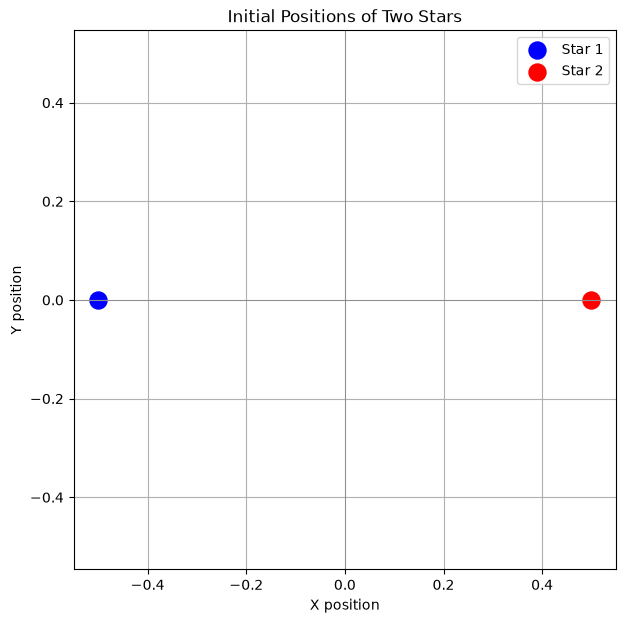

In [65]:
#Plot the initial positions of the two stars

plt.figure(figsize=(7, 7))

plt.scatter(position_1[0], position_1[1],
            color="blue", s=150, label="Star 1")

plt.scatter(position_2[0], position_2[1],
            color="red", s=150, label="Star 2")

plt.axhline(0, color="grey", linewidth=0.5)
plt.axvline(0, color="grey", linewidth=0.5)

plt.xlabel("X position")
plt.ylabel("Y position")
plt.title("Initial Positions of Two Stars")

plt.legend()
plt.grid()
plt.axis("equal")
plt.savefig("../results/plots/initial_positions.png", dpi=300, bbox_inches="tight")
plt.show()

In [66]:
def gravitational_acceleration(mass, displacement):

    distance = np.linalg.norm(displacement)

    acceleration = G * mass * displacement / distance**3

    return acceleration

In [67]:
#Calculate acceleration of Star 1

# Calculate displacement from Star 1 to Star 2

displacement_1 = position_2 - position_1

# Calculate gravitational acceleration

acceleration_1 = gravitational_acceleration(
    mass_2,
    displacement_1
)

print("Acceleration of Star 1:", acceleration_1)

Acceleration of Star 1: [1. 0.]


In [68]:
#Calculate acceleration of Star 2:

displacement_2 = position_1 - position_2

acceleration_2 = gravitational_acceleration(
    mass_1,
    displacement_2
)

print("Acceleration of Star 2:", acceleration_2)

Acceleration of Star 2: [-1.  0.]


In [69]:
#Check Newton's third law

force_1 = mass_1 * acceleration_1
force_2 = mass_2 * acceleration_2

print("Force on Star 1:", force_1)
print("Force on Star 2:", force_2)

print("Total force:", force_1 + force_2)

Force on Star 1: [1. 0.]
Force on Star 2: [-1.  0.]
Total force: [0. 0.]


In [70]:
#Simulation settings

dt = 0.001
total_time = 10.0

number_of_steps = int(total_time / dt)

print("Timestep:", dt)
print("Number of steps:", number_of_steps)

Timestep: 0.001
Number of steps: 10000


In [85]:
#Create copies of the initial conditions for the simulation
#Reset simulation positions and velocities

position_1_sim = position_1.copy()
position_2_sim = position_2.copy()

velocity_1_sim = velocity_1.copy()
velocity_2_sim = velocity_2.copy()


#Reset energy history and record initial energy

initial_kinetic = (
    0.5 * mass_1 * np.dot(velocity_1_sim, velocity_1_sim)
    + 0.5 * mass_2 * np.dot(velocity_2_sim, velocity_2_sim)
)

initial_separation = np.linalg.norm(
    position_2_sim - position_1_sim
)

initial_potential = (
    -G * mass_1 * mass_2 / initial_separation
)

initial_total_energy = initial_kinetic + initial_potential

total_energy_history = [initial_total_energy]


# Reset position recording and record initial positions

positions_1 = [position_1_sim.copy()]
positions_2 = [position_2_sim.copy()]


# Display initial energy

print("Initial kinetic energy:", initial_kinetic)
print("Initial potential energy:", initial_potential)
print("Initial total energy:", initial_total_energy)

Initial kinetic energy: 0.49999040999999994
Initial potential energy: -1.0
Initial total energy: -0.5000095900000001


In [86]:
# Run the orbital simulation

for step in range(number_of_steps):

    # Calculate displacement between the stars
    displacement_1 = position_2_sim - position_1_sim
    displacement_2 = position_1_sim - position_2_sim

    # Calculate gravitational acceleration
    acceleration_1 = gravitational_acceleration(
        mass_2, displacement_1
    )

    acceleration_2 = gravitational_acceleration(
        mass_1, displacement_2
    )

    # Save old velocities
    old_velocity_1 = velocity_1_sim.copy()
    old_velocity_2 = velocity_2_sim.copy()

    # Update velocities
    velocity_1_sim += acceleration_1 * dt
    velocity_2_sim += acceleration_2 * dt

    # Update positions using old velocities
    position_1_sim += old_velocity_1 * dt
    position_2_sim += old_velocity_2 * dt

    # Calculate kinetic energy
    kinetic_energy = (
        0.5 * mass_1 * np.dot(velocity_1_sim, velocity_1_sim)
        + 0.5 * mass_2 * np.dot(velocity_2_sim, velocity_2_sim)
    )

    # Calculate separation
    separation = np.linalg.norm(position_2_sim - position_1_sim)

    # Calculate potential energy
    potential_energy = -G * mass_1 * mass_2 / separation

    # Calculate total energy
    total_energy = kinetic_energy + potential_energy

    # Record energy
    total_energy_history.append(total_energy)

    # Record positions
    positions_1.append(position_1_sim.copy())
    positions_2.append(position_2_sim.copy())

print("Kinetic energy:", kinetic_energy)
print("Potential energy:", potential_energy)
print("Total energy:", total_energy)

Kinetic energy: 0.4834009878218182
Potential energy: -0.964866737862606
Total energy: -0.48146575004078784


In [87]:
print("Initial recorded energy:", total_energy_history[0])
print("Final recorded energy:", total_energy_history[-1])

energy_change = (
    total_energy_history[-1] - total_energy_history[0]
)

print("Change in energy:", energy_change)

Initial recorded energy: -0.5000095900000001
Final recorded energy: -0.48146575004078784
Change in energy: 0.01854383995921227


In [89]:
print("Star 1 initial velocity:", velocity_1)
print("Star 2 initial velocity:", velocity_2)

print("Star 1 simulation velocity:", velocity_1_sim)
print("Star 2 simulation velocity:", velocity_2_sim)

Star 1 initial velocity: [ 0.     -0.7071]
Star 2 initial velocity: [0.     0.7071]
Star 1 simulation velocity: [ 0.64188077 -0.2671892 ]
Star 2 simulation velocity: [-0.64188077  0.2671892 ]


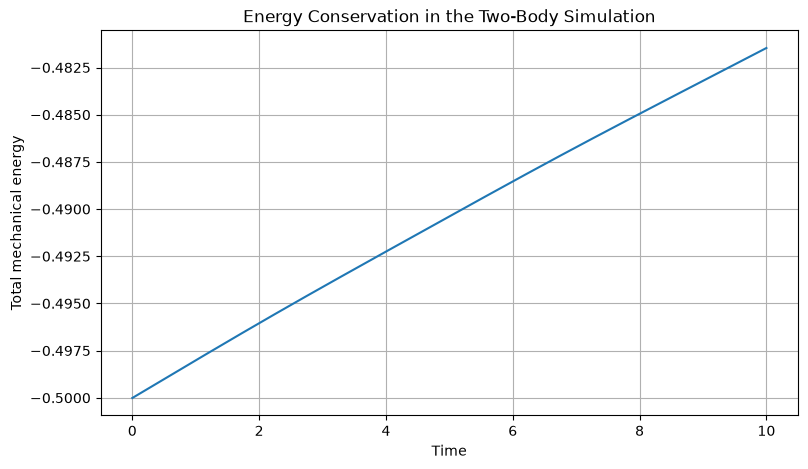

In [90]:
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(len(total_energy_history)) * dt,
    total_energy_history
)

plt.xlabel("Time")
plt.ylabel("Total mechanical energy")
plt.title("Energy Conservation in the Two-Body Simulation")

plt.grid()
plt.show()

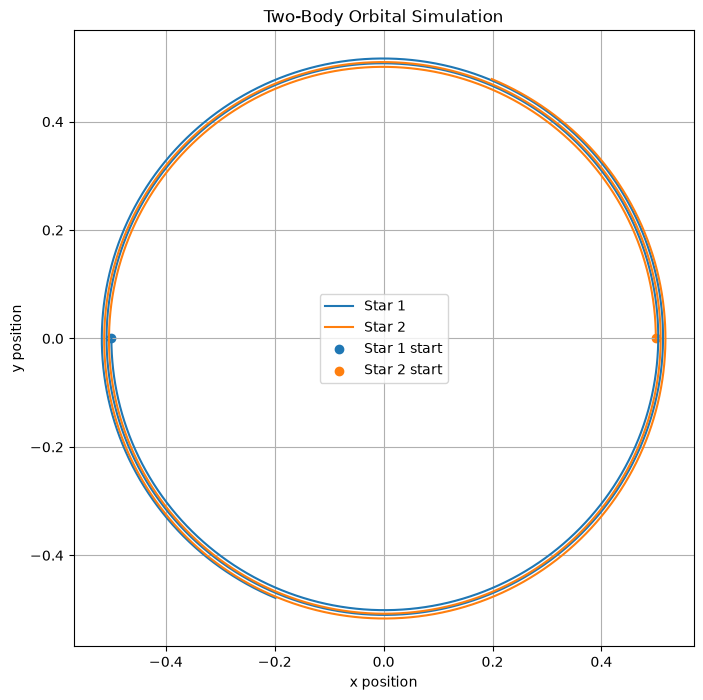

In [91]:
#Convert recorded positions into NumPy arrays

positions_1 = np.array(positions_1)
positions_2 = np.array(positions_2)

#Plot the trajectories
plt.figure(figsize=(8, 8))

plt.plot(
    positions_1[:, 0],
    positions_1[:, 1],
    label="Star 1"
)

plt.plot(
    positions_2[:, 0],
    positions_2[:, 1],
    label="Star 2"
)

#Mark the starting positions
plt.scatter(position_1[0], position_1[1], marker="o", label="Star 1 start")
plt.scatter(position_2[0], position_2[1], marker="o", label="Star 2 start")

plt.xlabel("x position")
plt.ylabel("y position")
plt.title("Two-Body Orbital Simulation")

plt.legend()
plt.grid()
plt.axis("equal")
plt.savefig("../results/plots/two-body_orbital_simulation.png", dpi=300, bbox_inches="tight")
plt.show()

In [92]:
#Convert recorded positions into NumPy arrays

positions_1_array = np.array(positions_1)
positions_2_array = np.array(positions_2)

#Calculate centre of mass at every timestep

centre_of_mass = (
    mass_1 * positions_1_array
    + mass_2 * positions_2_array
) / (mass_1 + mass_2)

#Calculate maximum distance from the origin

maximum_com_displacement = np.max(
    np.linalg.norm(centre_of_mass, axis=1)
)

print("Maximum centre-of-mass displacement:",
      maximum_com_displacement)

Maximum centre-of-mass displacement: 0.0
